# Momentum Has Its Moments — Decile WML Replication

**Reference:** Barroso & Santa-Clara (2015), *Momentum Has Its Moments*, Appendix A and Section 4, Equations (5)–(6).

**Goal:** Construct WML as the value-weighted highest-minus-lowest momentum decile (**P10 − P1**) from Kenneth French's **10 Portfolios Formed on Momentum**, rather than the distinct 2×3 `Mom` factor. Use the daily decile spread for the 126-day risk forecast and the independently published monthly decile spread for strategy returns.

**Evaluation convention:** Use the same available monthly observations through December 2011 for unmanaged, fixed-leverage, managed, and 2×-capped strategies. The fixed-exposure benchmark is descriptive and uses the in-sample mean managed weight. Results exclude financing and transaction costs.

**Historical limitation:** This uses the currently published Kenneth French decile series, not the original historical vintage or the Daniel–Moskowitz early-daily splice used by the paper. Thus it is a **decile-based partial replication**, not an exact replication of the paper's full 1927–2011 sample.

**Timing:** Momentum formation skips the most recent month (12–2 momentum). The volatility forecast uses 126 daily WML returns **including the final trading day of the estimation month**. The resulting leverage applies to the following month's WML return.

**Experiment structure:** Strategy construction and metrics are self-contained; downloaded decile datasets are cached under `data/raw/` for reproducibility.

**Code organization:** This notebook intentionally implements the paper equations independently for research validation. The verified monthly strategy logic is separately packaged in `src/momentum_risk_project/strategies.py`; this notebook does not import that module.

**Source of reported results:** Run `python run_all.py` or the ordered scripts first. This notebook independently explores/checks the equations; it does not create official exports. Official four-strategy returns, FF3 OLS, FF4 HAC and timing attribution are generated by `models.py`/`evaluation.py` into `results/replication/`. The untouched pre-refactor notebook is preserved in private history.

## 1. Load and Validate Momentum Decile Data

Load the **value-weighted** daily and monthly return tables from Kenneth French's `10_Portfolios_Prior_12_2` and `10_Portfolios_Prior_12_2_Daily` datasets. These are distinct from the standard 2×3 `Mom` factor. Each dataset is cached independently as a Parquet file; cached files are preferred on subsequent runs. Both WML series equal **P10 minus P1** in decimal returns. Daily and monthly WML are separate published portfolio series and need not agree under naive daily compounding.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, Image
from momentum_risk_project.paths import project_root
from momentum_risk_project.config import load_config, configured_path, config_digest

ROOT = project_root()
CONFIG = load_config(root=ROOT)
RESULTS = configured_path(CONFIG, "results", ROOT)
STUDY = configured_path(CONFIG, "study", ROOT)
BUILD_PATH = configured_path(CONFIG, "build", ROOT)
HIST = RESULTS / "replication/tables/paper_available_common"
if not (HIST / "run.json").exists():
    raise FileNotFoundError("Generate official results first: python run_all.py")
assert __import__("json").loads((HIST / "run.json").read_text())["config_digest"] == config_digest(CONFIG)

import matplotlib.pyplot as plt
import statsmodels.api as sm
from momentum_risk_project.data import clean_momentum
PROJECT_ROOT = ROOT
RAW_DIR = ROOT / "data/raw"
daily = clean_momentum(pd.read_parquet(configured_path(CONFIG,"kf_daily",ROOT)),"daily")
monthly = clean_momentum(pd.read_parquet(configured_path(CONFIG,"kf_monthly",ROOT)),"monthly")
daily_wml = daily.mom.rename("wml")
monthly_wml = monthly.mom.rename("wml")
unmanaged = monthly.mom.rename("unmanaged")
print("Exploration uses the same frozen KF inputs as the scripted official replication.")

Exploration uses the same frozen KF inputs as the scripted official replication.


## 2. Estimate Historical Momentum Volatility (Equation 5)

For holding month $t$, estimate monthly variance at the **end of month $t-1$**, using the last 126 daily momentum returns **including the final trading day of month $t-1$**:

$$\hat\sigma_t^2=\frac{21}{126}\sum_{j=0}^{125}r_{d_{t-1}-j}^2.$$

The daily rolling window is inclusive of its endpoint. The subsequent **one-month shift** maps the estimate from month $t-1$ to the return earned in month $t$. There is no additional daily shift. The estimator uses squared returns, not demeaned sample variance.


In [2]:
# Equation (5): include the final observed daily return at each month-end.
VOL_WINDOW = CONFIG["risk"]["window"]
TRADING_DAYS_PER_MONTH = CONFIG["risk"]["trading_days_per_month"]

daily_volatility = np.sqrt(
    TRADING_DAYS_PER_MONTH
    * daily["mom"].pow(2).rolling(
        window=VOL_WINDOW, min_periods=VOL_WINDOW
    ).mean()
)

monthly_volatility = daily_volatility.groupby(
    daily_volatility.index.to_period("M")
).last()
monthly_volatility.index.name = "month"

# Diagnostic: quantify the effect of unnecessarily excluding month-end returns.
excluded_endpoint_volatility = np.sqrt(
    TRADING_DAYS_PER_MONTH
    * daily["mom"].shift(1).pow(2).rolling(
        window=VOL_WINDOW, min_periods=VOL_WINDOW
    ).mean()
)
excluded_monthly_volatility = excluded_endpoint_volatility.groupby(
    excluded_endpoint_volatility.index.to_period("M")
).last()
excluded_monthly_volatility.index.name = "month"

volatility_window_audit = pd.DataFrame({
    "month_end_inclusive": monthly_volatility,
    "excluded_month_end": excluded_monthly_volatility,
}).dropna()
print("Maximum absolute volatility difference:",
      (volatility_window_audit["month_end_inclusive"]
       - volatility_window_audit["excluded_month_end"]).abs().max())
display(volatility_window_audit.head(8))


Maximum absolute volatility difference: 0.022335930871090676


,month_end_inclusive,excluded_month_end
month,,
1927-04,0.053473,0.053636
1927-05,0.051880,0.052201
1927-06,0.050227,0.050230
1927-07,0.046393,0.046440
1927-08,0.045694,0.045509
1927-09,0.043772,0.043529
1927-10,0.047424,0.047673
1927-11,0.051479,0.050216


## 3. Inspect the Volatility Forecast

Visualize how the estimated monthly risk changes over time. The estimate is based on squared daily returns, **not** demeaned sample variance.

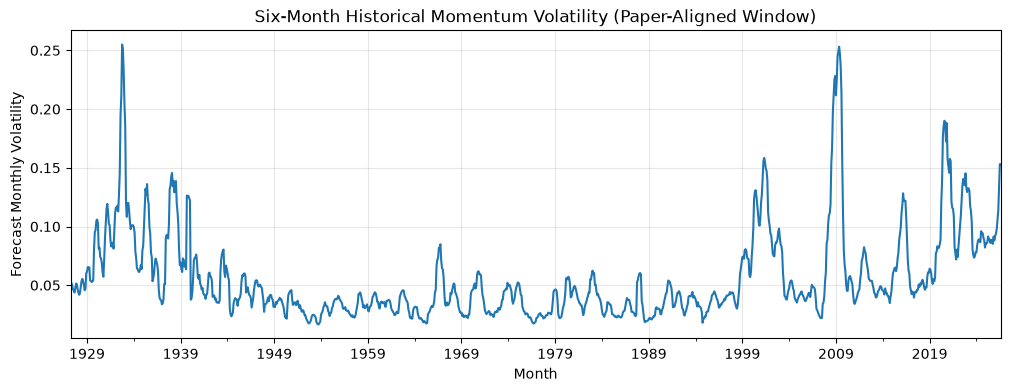

In [3]:
ax = monthly_volatility.dropna().plot(figsize=(12, 4))
ax.set_title("Six-Month Historical Momentum Volatility (Paper-Aligned Window)")
ax.set_xlabel("Month")
ax.set_ylabel("Forecast Monthly Volatility")
ax.grid(alpha=0.3)
plt.show()

## 4. Construct Volatility-Managed Momentum (Equation 6)

The annualized volatility target is **12%**, or $0.12/\sqrt{12}$ in monthly units. Estimate the risk through the **last trading day of month $t-1$**, then apply the resulting leverage to month $t$. Exactly one monthly shift is applied to the month-end weight series; there is **no daily shift** before the 126-day rolling calculation.

In [4]:
# Guard the calendar ordering assumed by the one-month lag.
assert isinstance(monthly.index, pd.PeriodIndex)
assert monthly.index.is_monotonic_increasing and monthly.index.is_unique
assert monthly.index.equals(
    pd.period_range(monthly.index[0], monthly.index[-1], freq="M")
), "Monthly WML returns must contain consecutive calendar months."
assert monthly_volatility.index.is_monotonic_increasing
assert monthly_volatility.index.is_unique

TARGET_ANNUAL_VOL = CONFIG["risk"]["annual_target"]
LEVERAGE_CAP = CONFIG["risk"]["leverage_cap"]
PAPER_END = CONFIG["windows"]["paper_available_common"][1]

# Equation (6): monthly target volatility divided by the lagged estimate.
# The weight used for holding month t is determined at the end of t-1.
target_monthly_vol = TARGET_ANNUAL_VOL / np.sqrt(12)
raw_monthly_weights = target_monthly_vol / monthly_volatility.replace(0, np.nan)
monthly_weights = raw_monthly_weights.shift(1).rename("weight")

managed_df = pd.DataFrame({
    "mom": monthly["mom"],
    "weight": monthly_weights,
})
managed_df["managed"] = managed_df["mom"] * managed_df["weight"]

# Independently verify the one-month execution lag.
expected_weights = (target_monthly_vol / monthly_volatility.replace(0, np.nan)).shift(1)
pd.testing.assert_series_equal(
    managed_df["weight"], expected_weights.rename("weight"),
    check_names=False,
)

print("Target annual volatility:", TARGET_ANNUAL_VOL)
display(managed_df.head(10))

Target annual volatility: 0.12


,mom,weight,managed
month,,,
1926-11,NaN,NaN,NaN
1926-12,NaN,NaN,NaN
1927-01,0.0308,NaN,NaN
1927-02,-0.0035,NaN,NaN
1927-03,0.0873,NaN,NaN
1927-04,0.0421,NaN,NaN
1927-05,0.0328,0.647827,0.021249
1927-06,0.0436,0.667718,0.029113
1927-07,0.0893,0.689684,0.061589


## 5. Define One Common Evaluation Sample and Fixed Leverage

**This is the single source of truth for the evaluation period.** First select months with available managed returns through 2011-12. Compute the mean managed weight **only on those months**; use that same fixed leverage in every subsequent table, plot, regression, and timing test. The cap is applied to the actual monthly exposure, not to the resulting return.

In [5]:
# Use only months with an implementable managed strategy return.
valid_months = managed_df.loc[CONFIG["windows"]["paper_available_common"][0]:PAPER_END, "managed"].dropna().index
paper_average_weight = managed_df.loc[valid_months, "weight"].mean()

comparison_fixed = pd.DataFrame({
    "unmanaged": managed_df.loc[valid_months, "mom"],
    "fixed_leverage": managed_df.loc[valid_months, "mom"] * paper_average_weight,
    "managed": managed_df.loc[valid_months, "managed"],
    "managed_cap_2x": (
        managed_df.loc[valid_months, "weight"].clip(upper=LEVERAGE_CAP)
        * managed_df.loc[valid_months, "mom"]
    ),
}).dropna()

# The following aliases keep the evaluation objects consistent.
paper_sample_returns = comparison_fixed
paper_weights = managed_df["weight"].reindex(comparison_fixed.index)
assert paper_weights.notna().all()
assert comparison_fixed.notna().all().all()
assert comparison_fixed.index.max() == pd.Period(PAPER_END, freq="M")

print("Common sample:", comparison_fixed.index.min(), "to", comparison_fixed.index.max())
print("Common observations:", len(comparison_fixed))
print("Paper-era mean managed leverage:", paper_average_weight)
display(comparison_fixed.head())

Common sample: 1927-07 to 2011-12
Common observations: 1014
Paper-era mean managed leverage: 0.8972507493690186


,unmanaged,fixed_leverage,managed,managed_cap_2x
month,,,,
1927-07,0.0893,0.080124,0.061589,0.061589
1927-08,0.0611,0.054822,0.045622,0.045622
1927-09,0.0768,0.068909,0.058223,0.058223
1927-10,0.0002,0.000179,0.000158,0.000158
1927-11,-0.0743,-0.066666,-0.054273,-0.054273


## 6. Leverage Diagnostics and Strategy Wealth

Inspect the distribution of **applied** managed weights over the common evaluation sample. Compare growth of $1 on a log scale; these wealth curves are stylized compounded factor returns without financing or transaction costs.

,Managed Weight
count,1014.000000
mean,0.897251
std,0.400608
min,0.135835
25%,0.608638
50%,0.868736
75%,1.146232
max,2.094142


Months with leverage > 2: 2
Months with leverage > 3: 0


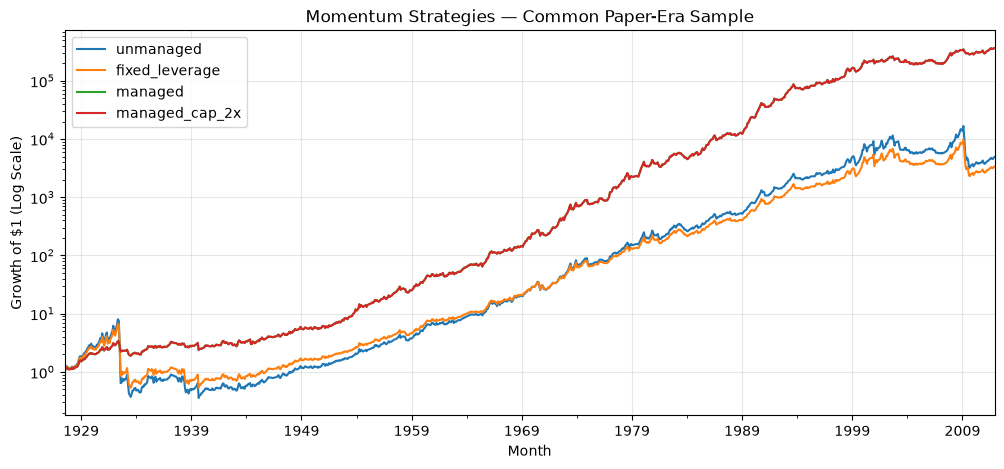

Terminal wealth:


,Terminal Wealth
unmanaged,4901.367359
fixed_leverage,3379.312768
managed,366393.213932
managed_cap_2x,365176.798373


In [6]:
display(paper_weights.describe().to_frame("Managed Weight"))
print("Months with leverage > 2:", int((paper_weights > 2).sum()))
print("Months with leverage > 3:", int((paper_weights > 3).sum()))

wealth_fixed = (1 + comparison_fixed).cumprod()
ax = wealth_fixed.plot(
    figsize=(12, 5),
    logy=True,
    title="Momentum Strategies — Common Paper-Era Sample",
)
ax.set_ylabel("Growth of $1 (Log Scale)")
ax.set_xlabel("Month")
ax.grid(alpha=0.3)
plt.show()
print("Terminal wealth:")
display(wealth_fixed.iloc[-1].to_frame("Terminal Wealth"))

## 7. Compare Risk and Return

Calculate annualized arithmetic mean, annualized volatility, zero-risk-free-rate Sharpe, CAGR, maximum drawdown, and terminal wealth. All strategies use the **identical** observations defined in Section 5.

The notebook defines the evaluation metrics locally, rather than importing an external performance module.

In [7]:
def performance_metrics(returns: pd.Series) -> pd.Series:
    """Compute annualized performance statistics from monthly decimal returns."""
    values = returns.dropna().astype(float)
    if values.empty:
        raise ValueError("Cannot evaluate an empty return series.")
    annual_return = values.mean() * 12
    annual_volatility = values.std(ddof=1) * np.sqrt(12)
    sharpe = annual_return / annual_volatility if annual_volatility > 0 else np.nan
    return pd.Series({
        "annual_return": annual_return,
        "annual_volatility": annual_volatility,
        "sharpe": sharpe,
    })

paper_sample_metrics = pd.DataFrame({
    strategy: performance_metrics(comparison_fixed[strategy])
    for strategy in comparison_fixed.columns
}).T
metrics_table = paper_sample_metrics

display(paper_sample_metrics.round(4))

,annual_return,annual_volatility,sharpe
unmanaged,0.1480,0.2745,0.5392
fixed_leverage,0.1328,0.2463,0.5392
managed,0.1667,0.1678,0.9933
managed_cap_2x,0.1666,0.1678,0.9931


## 8. Load Fama–French Three-Factor Data

Download the Fama–French three factors starting in 1926, rather than imposing an artificial 1963 cutoff. Use the intersection of the strategy and factor months for regressions **without changing the full-sample strategy performance comparison**. Report missing months explicitly.


In [8]:
ff3 = pd.read_parquet(configured_path(CONFIG,"ff3",ROOT))
ff3.index = pd.PeriodIndex(ff3.index,freq="M")
ff3.index.name = "month"
factor_columns_available = ["Mkt-RF", "SMB", "HML", "RF"]
factor_comparison = pd.concat(
    [comparison_fixed, ff3[factor_columns_available]],
    axis=1,
    join="inner",
).dropna()

if factor_comparison.empty:
    raise ValueError("No common complete months between strategy returns and FF3 factors")

missing_factor_months = comparison_fixed.index.difference(factor_comparison.index)
print("Full strategy sample:", comparison_fixed.index.min(), "to", comparison_fixed.index.max())
print("Full strategy observations:", len(comparison_fixed))
print("Factor regression sample:", factor_comparison.index.min(), "to", factor_comparison.index.max())
print("Factor regression observations:", len(factor_comparison))
print("Strategy months excluded from factor regressions:", len(missing_factor_months))
if len(missing_factor_months):
    print("Excluded months:", list(missing_factor_months[:20]))

assert factor_comparison.index.isin(comparison_fixed.index).all()
assert factor_comparison.index.is_unique


Full strategy sample: 1927-07 to 2011-12
Full strategy observations: 1014
Factor regression sample: 1927-07 to 2011-12
Factor regression observations: 1014
Strategy months excluded from factor regressions: 0


## 9. Three-Factor Regression: Unmanaged and Managed Strategies

Estimate the Fama–French three-factor intercept and loadings for each strategy. These are **OLS t-statistics** to match the simple paper-style regression; the HAC robustness checks follow later. The 1963–2011 factor-level sample should not be expected to reproduce coefficients reported for 1927–2011.

In [9]:
factor_columns = ["Mkt-RF", "SMB", "HML"]
X3 = sm.add_constant(factor_comparison[factor_columns])

factor_results = {}
for strategy in comparison_fixed.columns:
    model = sm.OLS(factor_comparison[strategy], X3).fit()
    factor_results[strategy] = {
        "Alpha (monthly)": model.params["const"],
        "Alpha t-stat": model.tvalues["const"],
        "Market Beta": model.params["Mkt-RF"],
        "SMB Beta": model.params["SMB"],
        "HML Beta": model.params["HML"],
        "R-squared": model.rsquared,
    }

factor_results = pd.DataFrame(factor_results).T
display(factor_results.round(4))

,Alpha (monthly),Alpha t-stat,Market Beta,SMB Beta,HML Beta,R-squared
unmanaged,0.0180,8.2627,-0.3676,-0.2117,-0.7360,0.2489
fixed_leverage,0.0162,8.2627,-0.3298,-0.1900,-0.6604,0.2489
managed,0.0159,10.8054,-0.0737,-0.1800,-0.2830,0.0876
managed_cap_2x,0.0159,10.8036,-0.0738,-0.1799,-0.2830,0.0876


## 10. Four-Factor Regression (FF3 + WML)

Add unmanaged WML as a fourth explanatory factor for the managed strategies. Report HAC standard errors with six lags. This is a **static linear factor-control exercise**, not proof of a causal timing premium.

In [10]:
four_factor_data = factor_comparison.copy()
four_factor_data["WML"] = four_factor_data["unmanaged"]
factor_cols = ["Mkt-RF", "SMB", "HML", "WML"]
X4 = sm.add_constant(four_factor_data[factor_cols])

four_factor_results = {}
for strategy in ["managed", "managed_cap_2x"]:
    model = sm.OLS(four_factor_data[strategy], X4).fit(
        cov_type="HAC", cov_kwds={"maxlags": 6}
    )
    four_factor_results[strategy] = {
        "Alpha (monthly)": model.params["const"],
        "Alpha t-stat (HAC)": model.tvalues["const"],
        "WML Beta": model.params["WML"],
        "Market Beta": model.params["Mkt-RF"],
        "SMB Beta": model.params["SMB"],
        "HML Beta": model.params["HML"],
        "R-squared": model.rsquared,
    }

four_factor_table = pd.DataFrame(four_factor_results).T
display(four_factor_table.round(4))

,Alpha (monthly),Alpha t-stat (HAC),WML Beta,Market Beta,SMB Beta,HML Beta,R-squared
managed,0.0058,5.0522,0.5577,0.1313,-0.0619,0.1274,0.7126
managed_cap_2x,0.0058,5.0512,0.5577,0.1312,-0.0618,0.1274,0.7126


## 11. Volatility-Timing Contribution

Subtract the **same fixed-leverage benchmark from Section 5** from dynamically managed returns. Estimate the mean difference using an intercept-only OLS with HAC(6) errors. The fixed benchmark's average weight is calculated ex post, so this is an **in-sample attribution test**, not an OOS implementable strategy.

In [11]:
timing_data = four_factor_data.copy()
sample_average_weight = paper_average_weight

timing_data["fixed_sample"] = timing_data["fixed_leverage"]
timing_data["timing_return"] = (
    timing_data["managed"] - timing_data["fixed_sample"]
)

X_mean = pd.DataFrame({"const": 1.0}, index=timing_data.index)
timing_model = sm.OLS(timing_data["timing_return"], X_mean).fit(
    cov_type="HAC", cov_kwds={"maxlags": 6}
)

print("Common-sample mean leverage:", sample_average_weight)
print("Monthly timing contribution:", timing_model.params["const"])
print("HAC t-stat:", timing_model.tvalues["const"])
print("HAC p-value:", timing_model.pvalues["const"])

Common-sample mean leverage: 0.8972507493690186
Monthly timing contribution: 0.002825173515678052
HAC t-stat: 2.1603309096358783
HAC p-value: 0.03074706177783467


## 12. Implementation Validation and Paper Alignment

Validate identical evaluation months, fixed leverage, one-month execution lag, and the **inclusive** 126-day risk window. The underlying series is now the value-weighted Kenneth French **decile WML (P10 − P1)**, not the 2×3 momentum factor. These checks establish internal consistency, not exact historical reproduction of the 1927–2011 paper results.

In [12]:
# Independently check the squared-return formula and the execution dates.
independent_daily_volatility = np.sqrt(
    21 * daily["mom"].pow(2).rolling(window=126, min_periods=126).mean()
)

target_month = pd.Period("2009-02", freq="M")
previous_month = target_month - 1
prior_month_dates = daily.index[daily.index.to_period("M") == previous_month]
last_prior_session = prior_month_dates[-1]
expected_volatility = np.sqrt(
    21 * daily["mom"].loc[:last_prior_session].tail(126).pow(2).mean()
)
expected_weight = (TARGET_ANNUAL_VOL / np.sqrt(12)) / expected_volatility
actual_weight = managed_df.loc[target_month, "weight"]

checks = {
    "Paper-era end date": comparison_fixed.index.max() == pd.Period("2011-12", freq="M"),
    "No missing strategy returns": comparison_fixed.notna().all().all(),
    "Regression months are a subset of strategy months": factor_comparison.index.isin(comparison_fixed.index).all(),
    "Common-sample mean weight": np.isclose(paper_average_weight, paper_weights.mean()),
    "Fixed exposure uses same mean": np.allclose(
        comparison_fixed["fixed_leverage"],
        comparison_fixed["unmanaged"] * paper_average_weight,
    ),
    "Managed return equals lagged weight times WML": np.allclose(
        comparison_fixed["managed"],
        managed_df.loc[comparison_fixed.index, "weight"]
        * comparison_fixed["unmanaged"],
    ),
    "2x cap uses capped weight": np.allclose(
        comparison_fixed["managed_cap_2x"],
        paper_weights.clip(upper=2.0) * comparison_fixed["unmanaged"],
    ),
    "Daily volatility includes current session": np.allclose(
        daily_volatility.dropna(), independent_daily_volatility.dropna()
    ),
    "February weight uses January month-end inclusive": np.isclose(
        actual_weight, expected_weight
    ),
    "January estimate includes final January trading day": (
        last_prior_session.to_period("M") == previous_month
    ),
}
validation_table = pd.DataFrame({
    "Check": list(checks), "Passed": list(checks.values())
})
display(validation_table)
print("Holding month:", target_month)
print("Volatility observation through:", last_prior_session)
print("Expected weight:", expected_weight)
print("Actual weight:", actual_weight)
assert validation_table["Passed"].all(), "Validation failed."
print("All implementation validation checks passed.")


,Check,Passed
0,Paper-era end date,True
1,No missing strategy returns,True
2,Regression months are a subset of strategy months,True
3,Common-sample mean weight,True
4,Fixed exposure uses same mean,True
5,Managed return equals lagged weight times WML,True
6,2x cap uses capped weight,True
7,Daily volatility includes current session,True
8,February weight uses January month-end inclusive,True
9,January estimate includes final January tradin...,True


Holding month: 2009-02
Volatility observation through: 2009-01-30 00:00:00
Expected weight: 0.1636150068489253
Actual weight: 0.1636150068489253
All implementation validation checks passed.


## 13. Replication Notes and Limitations

- **Portfolio definition:** Value-weighted Kenneth French momentum deciles, WML = P10 − P1, not the standard 2×3 `Mom` factor.
- **Daily and monthly inputs:** Official daily and monthly decile portfolio returns are loaded separately. The monthly spread is not computed by compounding the daily long-short spread.
- **Risk estimate:** Equation (5) uses the latest 126 daily squared WML returns **including the previous month-end trading day**; Equation (6) uses the next-month leverage determined at that month-end.
- **Historical comparability:** The currently available French data are not guaranteed to match the vintage used in the paper; the paper also supplements historical daily data with Daniel–Moskowitz. Do not interpret this notebook as exact full-sample Table 3 replication.
- **Sample:** The common evaluation sample ends in December 2011, after the 126-trading-day warm-up and monthly execution lag.
- **Fixed leverage:** Uses the in-sample average managed exposure and is descriptive rather than an out-of-sample trading rule.
- **Extensions:** The 2× cap and timing tests are extensions. Transaction costs, borrow fees, financing, and realistic trading constraints are excluded.
- **Validation:** Compare the newly computed unmanaged series and its statistics with the paper, and inspect any differences in sample dates and historical dataset vintages.

## 14. Verify package-generated replication outputs

Official aligned returns, risk weights, regression tables and metrics are generated by `scripts/03_replicate.py` into `results/replication`. The following checks independently derived notebook values against those reports and writes no official files.

In [13]:
# Official results were generated by models.py/evaluation.py through scripts/03_replicate.py.
# The independent notebook calculations validate them; this cell writes no result files.
api_official_returns = pd.read_csv(HIST / "strategy_returns.csv", index_col=0)
api_official_returns.index = pd.PeriodIndex(api_official_returns.index,freq="M",name="month")
pd.testing.assert_frame_equal(comparison_fixed,api_official_returns,check_freq=False,atol=1e-12)
api_official_ff3 = pd.read_csv(HIST / "ff3_regressions.csv", index_col=0)
api_official_ff4 = pd.read_csv(HIST / "ff4_HAC_regressions.csv", index_col=0)
pd.testing.assert_frame_equal(factor_results,api_official_ff3,atol=1e-12)
pd.testing.assert_frame_equal(four_factor_table,api_official_ff4,atol=1e-12)
print("Notebook derivations match the scripted returns and FF3/FF4 regressions.")

Notebook derivations match the scripted returns and FF3/FF4 regressions.


In [14]:

# Check how frequently the leverage cap is binding.
weights = paper_weights.dropna()

cap = LEVERAGE_CAP
binding = weights > cap

print(f"Maximum leverage: {weights.max():.4f}")
print(f"Average leverage: {weights.mean():.4f}")
print(f"Months above {cap:.1f}x: {binding.sum()}")
print(f"Share of months above {cap:.1f}x: {binding.mean():.2%}")

# Verify the capped strategy calculation.
expected_capped_returns = weights.clip(upper=cap) * comparison_fixed.loc[
    weights.index, "unmanaged"
]

pd.testing.assert_series_equal(
    expected_capped_returns,
    comparison_fixed.loc[weights.index, "managed_cap_2x"],
    check_names=False,
)

print("Leverage cap validation passed.")


Maximum leverage: 2.0941
Average leverage: 0.8973
Months above 2.0x: 2
Share of months above 2.0x: 0.20%
Leverage cap validation passed.


## Interpretation of the scripted replication

The displayed independent derivations must agree with the official package-generated returns/regressions. The historical volatility-managed strategy has higher Sharpe, lower volatility and less severe crash exposure than unmanaged WML. Use the generated metrics below for the current configured sample and source vintage; gross results do not establish tradable net profits. The fixed-leverage benchmark uses an ex-post historical mean for attribution. All formal calculations also run without this notebook through `models.py`, `evaluation.py` and `scripts/03_replicate.py`.

## Packaged API guide: reuse and verify the replication

The cells above independently implement the paper's equations. Downstream work can reuse the equivalent package functions without copying those research cells:

1. **Input:** `data.load_wml_decile_returns(refresh=False)` supplies daily/monthly decimal WML Series. For the checks below we use this notebook's already loaded `daily["mom"]` and `monthly["mom"]`, preserving its exact input snapshot.
2. **Risk:** `volatility.historical_volatility(daily_wml, window=126, trading_days_per_month=21)` returns a daily-indexed estimate in **monthly units**, using squared returns without demeaning. Select the actual final trading-day estimate of each month with `agg(lambda s: s.iloc[-1])`; this preserves an unavailable month-end estimate.
3. **Execution:** `strategies.volatility_managed_momentum(monthly_wml, month_end_sigma, target_volatility=0.12)` applies the one-calendar-month lag internally. Pass **unshifted origin-month sigma**; do not shift it again beforehand. Its output contains `mom`, `estimated_volatility`, `weight` (already applied) and `managed`. `unmanaged_momentum` returns the unscaled Series.
4. **Evaluation:** use an explicitly common, consecutive, complete monthly sample and `metrics.performance_metrics`. Warm-up forecasts remain NaN. Do not drop internal missing months and compound the remaining returns as an uninterrupted account.

The following cells compare the packaged outputs against this notebook's independent implementation on the same inputs and sample. Fixed leverage and the 2x cap remain explicit experiment choices, rather than hidden defaults of the strategy module.

In [15]:
from momentum_risk_project.volatility import historical_volatility
from momentum_risk_project.strategies import unmanaged_momentum, volatility_managed_momentum
from momentum_risk_project.metrics import performance_metrics as packaged_performance_metrics

api_daily_sigma = historical_volatility(
    daily["mom"], window=VOL_WINDOW,
    trading_days_per_month=TRADING_DAYS_PER_MONTH,
)
api_month_end_sigma = api_daily_sigma.groupby(
    api_daily_sigma.index.to_period("M")
).agg(lambda values: values.iloc[-1])

api_strategy = volatility_managed_momentum(
    monthly_returns=monthly["mom"],
    monthly_volatility=api_month_end_sigma,
    target_volatility=TARGET_ANNUAL_VOL,
)
np.testing.assert_allclose(api_daily_sigma, daily_volatility, equal_nan=True)
np.testing.assert_allclose(
    api_strategy["weight"], managed_df["weight"].reindex(api_strategy.index),
    equal_nan=True,
)
np.testing.assert_allclose(
    api_strategy["managed"], managed_df["managed"].reindex(api_strategy.index),
    equal_nan=True,
)

api_sample = comparison_fixed.index
assert api_sample.equals(pd.period_range(api_sample[0], api_sample[-1], freq="M"))
api_sample_weights = api_strategy.loc[api_sample, "weight"]
assert api_sample_weights.notna().all()
api_unmanaged = unmanaged_momentum(monthly["mom"]).reindex(api_sample)
api_common_returns = pd.DataFrame({
    "unmanaged": api_unmanaged,
    "fixed_leverage": api_unmanaged * api_sample_weights.mean(),
    "managed": api_strategy.loc[api_sample, "managed"],
    "managed_cap_2x": api_unmanaged * api_sample_weights.clip(upper=LEVERAGE_CAP),
})
pd.testing.assert_frame_equal(api_common_returns, comparison_fixed)
print("Packaged risk, lagged weights and all four strategy return series match the notebook.")

Packaged risk, lagged weights and all four strategy return series match the notebook.


In [16]:
api_metrics = pd.DataFrame({
    name: packaged_performance_metrics(api_common_returns[name])
    for name in api_common_returns
}).T
api_core_metrics = api_metrics[[
    "Annualized Mean Return", "Annualized Volatility", "Sharpe (rf=0)"
]].rename(columns={
    "Annualized Mean Return": "annual_return",
    "Annualized Volatility": "annual_volatility",
    "Sharpe (rf=0)": "sharpe",
})
pd.testing.assert_frame_equal(api_core_metrics, paper_sample_metrics)
print("Packaged performance metrics match the independently calculated core statistics.")
print(f"Common sample: {api_sample[0]} to {api_sample[-1]} ({len(api_sample)} months)")
display(api_metrics)


Packaged performance metrics match the independently calculated core statistics.
Common sample: 1927-07 to 2011-12 (1014 months)


,Annualized Mean Return,Annualized Volatility,Sharpe (rf=0),CAGR,Maximum Drawdown,Terminal Wealth
unmanaged,0.147986,0.274467,0.539175,0.105789,-0.955552,4901.367359
fixed_leverage,0.132780,0.246266,0.539175,0.100934,-0.920210,3379.312768
managed,0.166682,0.167807,0.993299,0.163712,-0.438301,366393.213932
managed_cap_2x,0.166641,0.167799,0.993100,0.163666,-0.438301,365176.798373


**Scope and downstream calls:** This API reproduces gross strategy returns and performance statistics. `models.paper_strategies` also packages the full four-strategy comparison, and `evaluation.factor_tests` packages the FF3 OLS, FF4 HAC and timing attribution. These formal results are generated by the ordered scripts; the calculations above independently validate them. Fixed-sample average leverage is an ex-post comparison benchmark, not a deployable forecast.

For the factor-level cost MVP, use `backtest.run_backtest` or `python -m momentum_risk_project.cli --help`, explained in Notebook 04 and `BACKTEST.md`. That turnover is a factor-scaling proxy. For reconstructed stock holdings and stock costs, use `wml_pipeline.load_build(...).backtest(weights, return_policy=..., transaction_cost_bps=...)`, as in Notebooks 03 and 05. That account accepts already applied holding-month weights and does not add another signal lag. Missing forecasts are not cash; valuation assumptions must be chosen explicitly. EWMA/GARCH model interfaces in README Section 9 remain planned extensions.

In [17]:
from momentum_risk_project.models import paper_strategies
from momentum_risk_project.evaluation import factor_tests

api_four, api_weights, api_sigma, api_fixed = paper_strategies(
    daily["mom"], monthly["mom"], start=CONFIG["windows"]["paper_available_common"][0],
    end=PAPER_END, annual_target=TARGET_ANNUAL_VOL, window=VOL_WINDOW,
    trading_days_per_month=TRADING_DAYS_PER_MONTH, leverage_cap=LEVERAGE_CAP,
)
pd.testing.assert_frame_equal(api_four, comparison_fixed)
api_factor_tables = factor_tests(api_four, ff3)
pd.testing.assert_frame_equal(api_factor_tables["ff3_regressions"], factor_results)
pd.testing.assert_frame_equal(api_factor_tables["ff4_HAC_regressions"], four_factor_table)
print("Standalone four-strategy and regression APIs match all independent notebook calculations.")
display(api_factor_tables["timing_HAC"])


Standalone four-strategy and regression APIs match all independent notebook calculations.


,monthly_timing_return,HAC_t,HAC_p,observations
0,0.002825,2.160331,0.030747,1014


## Package tests and notebook validation

Run these commands **in a terminal from the repository root**, using the project environment. The focused suite covers data, squared-return risk, strategy timing and metrics:

```bash
uv run pytest -p no:cacheprovider tests/test_data.py tests/test_volatility.py tests/test_strategies.py tests/test_metrics.py -q
```

Run the complete existing suite before integration:

```bash
uv run pytest -p no:cacheprovider tests/ -q
uv run pytest tests/test_pipeline.py -q
```

Unit tests use synthetic/local fixtures and do not require WRDS credentials or live market-data downloads. They validate implementation behavior; they do not establish equivalence to a particular CRSP/KF vintage or resolve missing economic payoffs. The executed API examples above additionally validate the shown notebook/data comparisons and require their documented local inputs. These checks are distinct from executing the entire notebook on the full research sample. If parameters, source inputs or valuation conventions change, rerun the relevant notebook and its comparisons as well as the tests. Planned EWMA/GARCH files and tests are not part of these implemented commands.